# Phase retrieval for a quantum wavefunction: the same math, 100 years apart

Schrödinger published his equation in 1926 [1]; this year it turns 100, and for a free particle it hasn't needed changing. A few years later, Pauli asked a question that is exactly this repository's problem [2]: **if you can only measure where a particle is likely to be, |ψ(x)|², can you still recover the wavefunction ψ, including its phase?**

**The connection, in programmer terms.** For a free particle, each momentum component of ψ just picks up a phase as time goes by: multiply by `exp(-1j*(hbar/m)*k**2*t/2)` in Fourier space. Fiber dispersion multiplies a light pulse by `exp(1j*beta2L*w**2/2)`. **That's the same function,** with `beta2L = -(hbar/m)*t`. So "the wavefunction spreading over time" and "a light pulse spreading in fiber" are one problem, and measuring |ψ|² at several times is measuring a pulse after several dispersions. The Gerchberg-Saxton algorithm [3], [4] doesn't care which one it's solving.

This notebook does it with an electron: SymPy for the physics, Python for the recovery, the same algorithm in **C (gcc in WSL)** and **CUDA (nvcc, cuFFT)**, a command-line driver with a **shebang** that reports errors through exit codes, and **Lean** proofs of the math. The measurements are simulated.

In [1]:
import sys, os, pathlib, shutil, subprocess, struct, tempfile, time, glob
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
sp.init_printing()
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
TOOLS = ROOT / 'tools' / 'qgs'
HBAR_M = 0.11576765                 # hbar / m_e in nm^2/fs
N, L = 1024, 200.0                  # grid points, box length in nm
x = (np.arange(N) - N//2)*(L/N); dx = L/N
k = 2*np.pi*np.fft.fftfreq(N, dx)
def evolve(psi, t): return np.fft.ifft(np.fft.fft(psi)*np.exp(-0.5j*HBAR_M*k**2*t))
print(f'electron: hbar/m = {HBAR_M} nm^2/fs; grid {N} points over {L:.0f} nm')

electron: hbar/m = 0.11576765 nm^2/fs; grid 1024 points over 200 nm


## 1. The physics in SymPy

- A plane wave e^{i(kx − ωt)} solves the free Schrödinger equation iħ ∂ψ/∂t = −(ħ²/2m) ∂²ψ/∂x² exactly when ω = ħk²/2m.
- So in Fourier space, time evolution is the multiplication U(k, t) = e^{−i(ħ/m)k²t/2}.
- Matching it to fiber dispersion e^{iβ₂Lω²/2} gives β₂L = −(ħ/m)t.

In [2]:
xs, ts, ks, hb, m = sp.symbols('x t k hbar m', real=True)
w_ = hb*ks**2/(2*m)
psi_pw = sp.exp(sp.I*(ks*xs - w_*ts))
lhs = sp.I*hb*sp.diff(psi_pw, ts); rhs = -hb**2/(2*m)*sp.diff(psi_pw, xs, 2)
print('plane wave solves the free Schrodinger equation when omega = hbar k^2 / 2m:', sp.simplify(lhs - rhs) == 0)
b2L = sp.symbols('beta_2L', real=True)
print('dispersion phase with beta2L = -(hbar/m) t equals the Schrodinger phase:',
      sp.simplify((b2L*ks**2/2).subs(b2L, -hb/m*ts) - (-(hb/m)*ks**2*ts/2)) == 0)
sig0 = 3.0
tau = sig0**2/HBAR_M
print(f'a 3 nm electron packet spreads on a time scale m sigma^2 / hbar = {tau:.0f} fs')
g = np.exp(-x**2/(4*sig0**2)); g /= np.sqrt(np.sum(abs(g)**2)*dx)
for t in (0, 40, 160):
    rho = abs(evolve(g, t))**2; w = np.sqrt(np.sum(x**2*rho)*dx)
    print(f'  t = {t:3d} fs: width {w:.3f} nm (formula sigma0 sqrt(1 + (hbar t / 2 m sigma0^2)^2) = {sig0*np.sqrt(1 + (HBAR_M*t/(2*sig0**2))**2):.3f} nm)')

plane wave solves the free Schrodinger equation when omega = hbar k^2 / 2m: True
dispersion phase with beta2L = -(hbar/m) t equals the Schrodinger phase: True
a 3 nm electron packet spreads on a time scale m sigma^2 / hbar = 78 fs
  t =   0 fs: width 3.000 nm (formula sigma0 sqrt(1 + (hbar t / 2 m sigma0^2)^2) = 3.000 nm)
  t =  40 fs: width 3.098 nm (formula sigma0 sqrt(1 + (hbar t / 2 m sigma0^2)^2) = 3.098 nm)
  t = 160 fs: width 4.305 nm (formula sigma0 sqrt(1 + (hbar t / 2 m sigma0^2)^2) = 4.305 nm)


## 2. Recovering ψ from densities alone (Python)

The test wavefunction is two wave packets moving toward each other, the second with a relative phase of π/2. That phase is exactly the information |ψ|² hides. The "measurements" are |ψ(x, t)|² at a few times, and Gerchberg-Saxton goes back and forth between them. The score is the **fidelity** |⟨ψ_rec|ψ⟩|², 1 for a perfect recovery. It ignores the global phase, which is physically meaningless.

In [3]:
def pk(x0, s, k0, ph): return np.exp(-(x - x0)**2/(4*s**2) + 1j*k0*x + 1j*ph)
psi0 = pk(-10, 3, 0.4, 0) + 0.8*pk(12, 2.5, -0.3, np.pi/2)
psi0 /= np.sqrt(np.sum(abs(psi0)**2)*dx)

def recover(times, n_iter=300):
    amps = [np.abs(evolve(psi0, t)) for t in times]
    psi = amps[0].astype(complex)
    for _ in range(n_iter):
        for a, t in zip(amps, times):
            psi = evolve(a*np.exp(1j*np.angle(evolve(psi, t))), -t)
    return psi

results = {}
for times in ([0, 20, 40, 80, 160], [0, 40, 160], [0, 80], [0]):
    psi_r = recover(times) if len(times) > 1 else np.sqrt(abs(psi0)**2).astype(complex)
    fid = abs(np.sum(np.conj(psi_r)*psi0)*dx)**2
    results[len(times)] = (times, psi_r, fid)
    print(f'{len(times)} measurement time(s) {times} fs: fidelity {fid:.6f}')
print('-> one density alone loses the phase; two are not enough here; three or more recover psi completely')

5 measurement time(s) [0, 20, 40, 80, 160] fs: fidelity 1.000000


3 measurement time(s) [0, 40, 160] fs: fidelity 1.000000
2 measurement time(s) [0, 80] fs: fidelity 0.743945
1 measurement time(s) [0] fs: fidelity 0.104782
-> one density alone loses the phase; two are not enough here; three or more recover psi completely


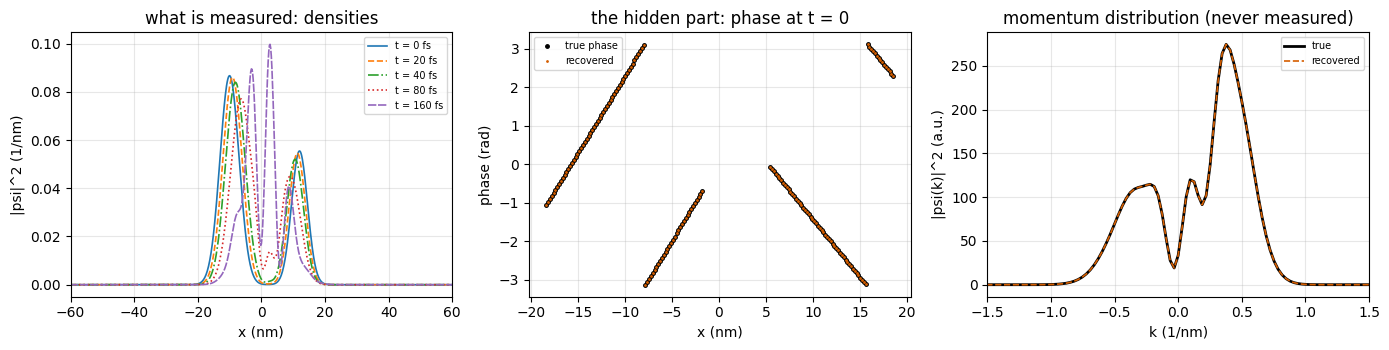

fidelity 1.000000. Figure: left, the five measured position densities (one line style each), spreading and
interfering as time goes on; middle, the phase of psi at t = 0 where the particle is likely to be, true (black circles) and
recovered (orange dots), on top of each other; right, the momentum distribution, true (solid black) and recovered
(dashed orange): it was never measured, yet it comes out right because the phase was recovered.


In [4]:
times, psi_r, fid = results[5]
g = np.angle(np.sum(np.conj(psi_r)*psi0)); psi_r = psi_r*np.exp(1j*g)          # remove the global phase
fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(14, 3.6))
for t, st in zip(times, ['-', '--', '-.', ':', (0, (5, 1))]):
    a1.plot(x, abs(evolve(psi0, t))**2, ls=st, lw=1.2, label=f't = {t} fs')
a1.set_xlim(-60, 60); a1.set_xlabel('x (nm)'); a1.set_ylabel('|psi|^2 (1/nm)'); a1.set_title('what is measured: densities'); a1.legend(fontsize=7)
mask = abs(psi0)**2 > 0.02*np.max(abs(psi0)**2)
a2.plot(x[mask], np.angle(psi0[mask]), 'o', color='#000000', ms=2.5, label='true phase')
a2.plot(x[mask], np.angle(psi_r[mask]), '.', color='#D55E00', ms=2, label='recovered')
a2.set_xlabel('x (nm)'); a2.set_ylabel('phase (rad)'); a2.set_title('the hidden part: phase at t = 0'); a2.legend(fontsize=7)
ks_sorted = np.fft.fftshift(k)
a3.plot(ks_sorted, np.fft.fftshift(abs(np.fft.fft(psi0))**2), color='#000000', ls='-', lw=2, label='true')
a3.plot(ks_sorted, np.fft.fftshift(abs(np.fft.fft(psi_r))**2), color='#D55E00', ls='--', lw=1.2, label='recovered')
a3.set_xlim(-1.5, 1.5); a3.set_xlabel('k (1/nm)'); a3.set_ylabel('|psi(k)|^2 (a.u.)'); a3.set_title('momentum distribution (never measured)'); a3.legend(fontsize=7)
for a in (a1, a2, a3): a.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f'fidelity {fid:.6f}. Figure: left, the five measured position densities (one line style each), spreading and')
print('interfering as time goes on; middle, the phase of psi at t = 0 where the particle is likely to be, true (black circles) and')
print('recovered (orange dots), on top of each other; right, the momentum distribution, true (solid black) and recovered')
print('(dashed orange): it was never measured, yet it comes out right because the phase was recovered.')

## 3. The same algorithm in C, compiled with gcc in WSL

`tools/qgs/gs_wavefunction.c` is plain C11 with its own radix-2 FFT: no libraries beyond `-lm`. The notebook writes the densities to a binary file, runs the program under WSL (Ubuntu), and reads ψ back.

**No exceptions.** C doesn't have them. Every failure is a **return code** the caller has to check: 0 ok, 2 bad arguments, 3 file error, 4 out of memory, 5 grid size not a power of 2. In a shell that's `$?`. The cells below show the success case and two failure cases.

In [5]:
WORK = pathlib.Path(tempfile.mkdtemp(prefix='qpr_'))
def write_densities(path, times):
    with open(path, 'wb') as f:
        f.write(struct.pack('<iidd', N, len(times), dx, HBAR_M)); f.write(np.array(times, '<f8').tobytes())
        for t in times: f.write((abs(evolve(psi0, t))**2).astype('<f8').tobytes())
def read_psi(path):
    raw = np.fromfile(path, '<f8'); return raw[0::2] + 1j*raw[1::2]
def wsl_path(p):
    p = str(pathlib.Path(p).resolve()).replace('\\', '/'); return f'/mnt/{p[0].lower()}{p[2:]}'
TIMES = [0.0, 20.0, 40.0, 80.0, 160.0]
write_densities(WORK / 'densities.bin', TIMES)
WSL = shutil.which('wsl')
if WSL:
    b = subprocess.run([WSL, '-e', 'gcc', '-O2', '-Wall', '-Wextra', '-std=c11', wsl_path(TOOLS / 'gs_wavefunction.c'), '-o', '/tmp/gs_wavefunction', '-lm'], capture_output=True, text=True)
    print('gcc (WSL) exit code:', b.returncode, '| warnings:', b.stderr.strip() or 'none')
    t0 = time.perf_counter()
    r = subprocess.run([WSL, '-e', '/tmp/gs_wavefunction', wsl_path(WORK / 'densities.bin'), wsl_path(WORK / 'psi_c.bin'), '300'], capture_output=True, text=True)
    t_c = time.perf_counter() - t0
    psi_c = read_psi(WORK / 'psi_c.bin')
    print(f'C run exit code {r.returncode}, misfit {r.stdout.strip()}, fidelity {abs(np.sum(np.conj(psi_c)*psi0)*dx)**2:.6f}, {t_c*1e3:.0f} ms (including WSL start-up)')
    print('  missing input file  -> exit code', subprocess.run([WSL, '-e', '/tmp/gs_wavefunction', '/tmp/no_such_file.bin', '/tmp/o.bin', '10'], capture_output=True).returncode)
    print('  wrong argument count -> exit code', subprocess.run([WSL, '-e', '/tmp/gs_wavefunction'], capture_output=True).returncode)
else:
    print('WSL not found: skipping the gcc build')

gcc (WSL) exit code: 0 | warnings: none
C run exit code 0, misfit 3.644e-13, fidelity 1.000000, 183 ms (including WSL start-up)


  missing input file  -> exit code 3
  wrong argument count -> exit code 2


## 4. The same algorithm in CUDA, compiled with nvcc (cuFFT)

`tools/qgs/gs_wavefunction.cu` runs every FFT, propagator and amplitude replacement on the GPU, with cuFFT for the transforms. Error handling uses the same return codes, plus 6 for a CUDA or cuFFT error: every CUDA call is checked and turned into an exit code, with no exceptions.

**Honest timing:** a single 1024-point wavefunction is far too small to keep a GPU busy. Each iteration is a few tiny kernel launches, so the CPU versions can win here. The GPU pays off when thousands of wavefunctions or pulses are recovered at once.

In [6]:
NVCC = shutil.which('nvcc') or (glob.glob(r'C:\Program Files\NVIDIA GPU Computing Toolkit\CUDA\v*\bin\nvcc.exe') or [None])[-1]
VC = (glob.glob(r'C:\Program Files\Microsoft Visual Studio\*\*\VC\Auxiliary\Build\vcvars64.bat') or [None])[0]
exe_cu = WORK / 'gs_wavefunction_cuda.exe'; have_cu = False
if NVCC and VC:
    bat = WORK / 'b.bat'
    bat.write_text(f'@echo off\ncall "{VC}" >nul 2>nul\n"{NVCC}" -O2 -arch=sm_89 "{TOOLS / "gs_wavefunction.cu"}" -o "{exe_cu}" -lcufft\nexit /b %ERRORLEVEL%\n')
    b = subprocess.run(['cmd', '/c', str(bat)], capture_output=True, text=True, timeout=900)
    print('nvcc exit code:', b.returncode); have_cu = b.returncode == 0
else:
    print('nvcc or MSVC not found: skipping the CUDA build')
if have_cu:
    t0 = time.perf_counter()
    r = subprocess.run([str(exe_cu), str(WORK / 'densities.bin'), str(WORK / 'psi_cu.bin'), '300'], capture_output=True, text=True)
    t_cu = time.perf_counter() - t0
    mis, gpu_ms = r.stdout.split()
    psi_cu = read_psi(WORK / 'psi_cu.bin')
    print(f'CUDA exit code {r.returncode}, misfit {mis}, fidelity {abs(np.sum(np.conj(psi_cu)*psi0)*dx)**2:.6f}; GPU loop {float(gpu_ms):.0f} ms, whole program {t_cu*1e3:.0f} ms')
t0 = time.perf_counter(); recover(TIMES); t_np = time.perf_counter() - t0
print(f'NumPy, same 300 iterations: {t_np*1e3:.0f} ms')

nvcc exit code: 0


CUDA exit code 0, misfit 9.336e-15, fidelity 1.000000; GPU loop 105 ms, whole program 284 ms


NumPy, same 300 iterations: 414 ms


## 5. A command-line driver with a shebang

`tools/qgs/run_qgs.py` starts with `#!/usr/bin/env python3`. On Linux or WSL, after `chmod +x`, you run it as `./run_qgs.py ./gs_wavefunction`, and the shebang line tells the system which interpreter to use. It builds the test wavefunction, runs any compiled version (C or CUDA), and checks the fidelity.

It also handles errors **without exceptions**: it checks its arguments and the program's exit code, prints a one-line message, and returns a code (0 recovered, 1 ran but did not recover, 2 bad arguments, 3 program missing or failed), so a shell script can test `$?`. No Python traceback ever reaches the user.

In [7]:
print(open(TOOLS / 'run_qgs.py', encoding='utf-8').readline().strip(), '  <- the shebang line')
drv = [sys.executable, str(TOOLS / 'run_qgs.py')]
if have_cu:
    r = subprocess.run(drv + [str(exe_cu)], capture_output=True, text=True); print('with the CUDA build  ->', r.stdout.strip(), '| exit code', r.returncode)
r = subprocess.run(drv + ['no_such_program'], capture_output=True, text=True); print('missing program      ->', r.stderr.strip(), '| exit code', r.returncode)
r = subprocess.run(drv, capture_output=True, text=True); print('no arguments         -> exit code', r.returncode)

#!/usr/bin/env python3   <- the shebang line


with the CUDA build  -> gs_wavefunction_cuda.exe: misfit 9.336e-15, fidelity |<psi_rec|psi>|^2 = 1.000000, GPU time 91.971 ms | exit code 0
missing program      -> executable not found: no_such_program | exit code 3


no arguments         -> exit code 2


## 6. The math, proved in Lean

`lean/QuantumPhaseRetrieval.lean` (Lean 4 + Mathlib):

| theorem | what it proves |
|---|---|
| `U_unit` | the free propagator has length 1: probability is conserved |
| `U_compose` | evolving t₁ then t₂ equals evolving t₁ + t₂ |
| `U_undo` | evolving back by −t undoes it (the "return to t = 0" step of GS) |
| `conj_reverses_time` | conjugating ψ reverses time, so densities at t = 0 and positive times are needed to tell ψ from conj(ψ) |
| `global_phase_invisible` | a global phase changes no density, and in quantum mechanics it has no physical meaning anyway |
| `schrodinger_is_dispersion` | the Schrödinger phase equals the fiber-dispersion phase when β₂L = −(ħ/m)t |
| `gaussian_spreads` | a free Gaussian packet's width never shrinks below its starting width |

In [8]:
import re
lean_file = ROOT / 'lean' / 'QuantumPhaseRetrieval.lean'
names = re.findall(r'^theorem (\w+)', lean_file.read_text(encoding='utf-8'), re.M)
proj = pathlib.Path.home() / 'lean' / 'NavierStokesAndEuler'
if proj.exists() and shutil.which('lake'):
    r = subprocess.run(['lake', 'env', 'lean', str(lean_file)], cwd=proj, capture_output=True, text=True, timeout=1800)
    msg = r.stdout + r.stderr
    print(f'Lean + Mathlib exit code {r.returncode}: {len(names)} theorems accepted' if r.returncode == 0 and 'sorry' not in msg else
          ('NOT CHECKED: out of memory while loading Mathlib' if 'failed to read file' in msg else msg[-1500:]))
else:
    print(f'Lean + Mathlib not found here: {len(names)} theorems not checked on this machine')
print('  ' + ', '.join(names))

Lean + Mathlib exit code 0: 7 theorems accepted
  U_unit, U_compose, U_undo, conj_reverses_time, global_phase_invisible, schrodinger_is_dispersion, gaussian_spreads


## 7. How fast a wave packet spreads, with the derivatives written out

A free electron that starts as a Gaussian of width σ₀ does not stay that size. Each momentum component moves at its own speed, so the packet spreads, the same way a short optical pulse spreads in fiber. Its position variance is

$$\sigma^2(t) = \sigma_0^2 + \left(\frac{(\hbar/m)\,t}{2\sigma_0}\right)^2 .$$

Below, SymPy takes the derivatives one step at a time (chain rule shown, not skipped), torch checks the same slope by automatic differentiation, the Python simulation from section 2 checks the formula itself, and Lean proves the main facts.

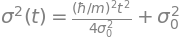

step 1, inner derivative du/dt:


step 2, outer times inner, 2u * du/dt:


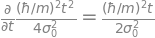

step 3, the slope of the variance:


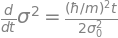

second derivative (constant, so sigma^2 is a parabola in t):


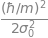

where the slope is zero: t = [0] -> narrowest at t = 0
slope of the width:


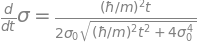

at long times the width grows at a constant speed:


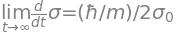

In [9]:
from IPython.display import display
s0, hm_, t_ = sp.symbols(r'sigma_0 (\hbar/m) t', positive=True)
u = hm_*t_/(2*s0)                                  # the inner function
var = s0**2 + u**2
display(sp.Eq(sp.Symbol(r'\sigma^{2}(t)'), var))

# chain rule, one step at a time: d/dt [u^2] = 2u * du/dt
du = sp.diff(u, t_)
print('step 1, inner derivative du/dt:');            display(sp.Eq(sp.Derivative(u, t_), du))
print('step 2, outer times inner, 2u * du/dt:');      display(sp.Eq(sp.Derivative(u**2, t_), 2*u*du))
dvar = sp.simplify(2*u*du)
assert sp.simplify(dvar - sp.diff(var, t_)) == 0     # same answer sp.diff gets in one call
print('step 3, the slope of the variance:');          display(sp.Eq(sp.Derivative(sp.Symbol(r'\sigma^{2}'), t_), dvar))
print('second derivative (constant, so sigma^2 is a parabola in t):'); display(sp.diff(var, t_, 2))
tau = sp.Symbol('t', real=True)                      # allow negative t for this one
print('where the slope is zero: t =', sp.solve(sp.diff(var.subs(t_, tau), tau), tau), '-> narrowest at t = 0')

# the width itself, sigma = sqrt(var): d sigma/dt = (d var/dt) / (2 sqrt(var))
sig = sp.sqrt(var)
dsig = sp.simplify(sp.diff(sig, t_))
print('slope of the width:');                         display(sp.Eq(sp.Derivative(sp.Symbol('sigma'), t_), dsig))
print('at long times the width grows at a constant speed:')
display(sp.Eq(sp.Limit(sp.Derivative(sp.Symbol('sigma'), t_), t_, sp.oo), sp.limit(dsig, t_, sp.oo)))

torch 2.11.0+cu128: autograd d(sigma)/dt vs SymPy formula, max difference 4.2e-17 nm/fs
   t =     0 fs   d(sigma)/dt = 0.00000 nm/fs
   t =    50 fs   d(sigma)/dt = 0.01697 nm/fs
   t =   100 fs   d(sigma)/dt = 0.02381 nm/fs
   t =   150 fs   d(sigma)/dt = 0.02629 nm/fs
   t =   200 fs   d(sigma)/dt = 0.02736 nm/fs
   t =   250 fs   d(sigma)/dt = 0.02790 nm/fs
   t =   300 fs   d(sigma)/dt = 0.02820 nm/fs

simulated width vs formula: max difference 1.8e-15 nm


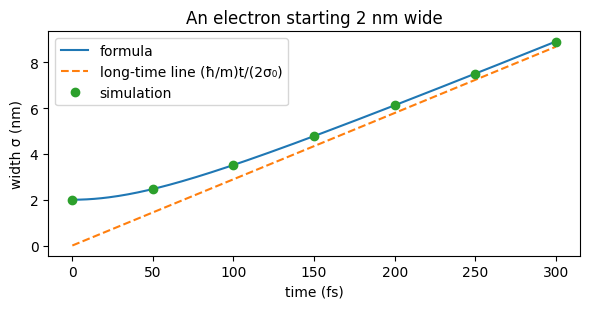

In [10]:
# torch autograd: the same slope with no formula typed in, just the variance itself
try:
    import torch
    sig0, hmv = 2.0, HBAR_M                                      # 2 nm start, electron
    tt = torch.linspace(0, 300, 7, dtype=torch.float64, requires_grad=True)
    sigma_t = torch.sqrt(sig0**2 + (hmv*tt/(2*sig0))**2)
    (g,) = torch.autograd.grad(sigma_t.sum(), tt)
    f_sym = sp.lambdify(t_, dsig.subs({s0: sig0, hm_: hmv}), 'numpy')
    err = np.max(np.abs(g.numpy() - f_sym(tt.detach().numpy())))
    print(f'torch {torch.__version__}: autograd d(sigma)/dt vs SymPy formula, max difference {err:.1e} nm/fs')
    for ti, gi in zip(tt.detach().numpy(), g.numpy()): print(f'   t = {ti:5.0f} fs   d(sigma)/dt = {gi:.5f} nm/fs')
except ImportError:
    print('torch is not installed in this kernel; skipping the autograd check')

# the simulation from section 2: evolve a real Gaussian and measure its width
sig0 = 2.0
psi_g = np.exp(-x**2/(4*sig0**2)).astype(complex)
t_list = np.array([0, 50, 100, 150, 200, 250, 300.0])
meas = []
for tv in t_list:
    p = np.abs(evolve(psi_g, tv))**2; p /= p.sum()
    mu = np.sum(x*p); meas.append(np.sqrt(np.sum((x - mu)**2*p)))
meas = np.array(meas)
theory = np.sqrt(sig0**2 + (HBAR_M*t_list/(2*sig0))**2)
print(f'\nsimulated width vs formula: max difference {np.max(np.abs(meas - theory)):.1e} nm')
fig, ax = plt.subplots(figsize=(6, 3.2))
tf = np.linspace(0, 300, 200)
ax.plot(tf, np.sqrt(sig0**2 + (HBAR_M*tf/(2*sig0))**2), label='formula')
ax.plot(tf, HBAR_M*tf/(2*sig0), '--', label='long-time line (ħ/m)t/(2σ₀)')
ax.plot(t_list, meas, 'o', label='simulation')
ax.set_xlabel('time (fs)'); ax.set_ylabel('width σ (nm)'); ax.set_title('An electron starting 2 nm wide')
ax.legend(); fig.tight_layout(); plt.show()

`lean/WavePacketSpreading.lean` (Lean 4 + Mathlib) proves the same facts:

| theorem | what it proves |
|---|---|
| `var_other_form` | the two common ways of writing σ²(t) agree |
| `var_parabola` | σ²(t) is a parabola in t |
| `var_deriv` | d(σ²)/dt = (ħ/m)²t / (2σ₀²), as a `HasDerivAt` statement |
| `var_second_deriv` | the second derivative is the constant (ħ/m)² / (2σ₀²) |
| `narrowest_at_zero` | the packet is narrowest at t = 0 |
| `slope_zero_at_zero` | the slope there is zero |
| `time_symmetric` | it spreads the same way forward and backward in time |
| `width_at_least_linear` | σ(t) ≥ \|(ħ/m)t / (2σ₀)\|: at long times it grows linearly |
| `narrower_spreads_faster` | a smaller σ₀ spreads faster (tight in position means wide in momentum) |

In [11]:
import re
lean_file = ROOT / 'lean' / 'WavePacketSpreading.lean'
names = re.findall(r'^theorem (\w+)', lean_file.read_text(encoding='utf-8'), re.M)
proj = pathlib.Path.home() / 'lean' / 'NavierStokesAndEuler'
if proj.exists() and shutil.which('lake'):
    r = subprocess.run(['lake', 'env', 'lean', str(lean_file)], cwd=proj, capture_output=True, text=True, timeout=1800)
    msg = r.stdout + r.stderr
    print(f'Lean + Mathlib exit code {r.returncode}: {len(names)} theorems accepted' if r.returncode == 0 and 'sorry' not in msg else
          ('NOT CHECKED: out of memory while loading Mathlib' if 'failed to read file' in msg else msg[-1500:]))
else:
    print(f'Lean + Mathlib not found here: {len(names)} theorems not checked on this machine')
print('  ' + ', '.join(names))

Lean + Mathlib exit code 0: 9 theorems accepted
  var_other_form, var_parabola, var_deriv, var_second_deriv, narrowest_at_zero, slope_zero_at_zero, time_symmetric, width_at_least_linear, narrower_spreads_faster


## What this shows

- **One algorithm, two kinds of physics.** Gerchberg-Saxton recovers an electron's wavefunction from position densities exactly as it recovers an optical pulse from dispersed intensities, because free Schrödinger evolution *is* dispersion.
- **Pauli's question has a practical answer:** one density can't do it, two weren't enough here, and three or more recovered this ψ with fidelity 1.000000, including its momentum distribution, which was never measured.
- **Spreading, derived three ways.** SymPy's step-by-step derivative, torch autograd and the simulation agree on how fast a packet widens, and Lean proves it is narrowest at t = 0 and grows linearly at long times.
- **Same answer in Python, C and CUDA,** with errors reported as exit codes throughout.
- **Limits:** one dimension, a free particle (no potential), noise-free simulated densities, and one test wavefunction. Real measurements of electron or atom densities at several times would add noise and finite resolution.

## References

[1] E. Schrödinger, "Quantisierung als Eigenwertproblem," *Annalen der Physik*, vol. 79, pp. 361–376, 1926.
[2] W. Pauli, "Die allgemeinen Prinzipien der Wellenmechanik," in *Handbuch der Physik*, vol. 24, Springer, 1933 (the question of recovering ψ from position and momentum densities).
[3] R. W. Gerchberg and W. O. Saxton, "A practical algorithm for the determination of phase from image and diffraction plane pictures," *Optik*, vol. 35, no. 2, pp. 237–246, 1972.
[4] D. R. Solli, S. Gupta, and B. Jalali, "Optical phase recovery in the dispersive Fourier transform," *Appl. Phys. Lett.*, vol. 95, no. 23, p. 231108, 2009, doi: 10.1063/1.3271678.

*[4] was checked against the PDF; [1]–[3] are from memory (for [3], title and authors match the PDF). Confirm before citing in a paper.*